In [ ]:
GAMMA = 0.9    # Faktor diskonto
THETA = 1e-6   # Batas perubahan nilai untuk berhenti
MDP = {
    "Rumah":   [("Jalan raya", "Kampus", 4),
                ("Jalan alternatif", "Simpang", 0)],
    "Simpang": [("Lanjut", "Kampus", 10)],
    "Kampus":  [],
}

def nilai_aksi(V, reward, tujuan, gamma):
    """Reward langsung ditambah nilai masa depan yang didiskon."""
    return reward + gamma * V[tujuan]

def perbarui_nilai(mdp, V, gamma):
    """Satu iterasi: hitung nilai baru semua state dari nilai lama."""
    V_baru, delta = {}, 0.0
    for state, aksi_list in mdp.items():
        if not aksi_list:
            V_baru[state] = 0.0          # state terminal selalu bernilai 0
        else:
            V_baru[state] = max(         # nilai state = nilai aksi terbaik
                nilai_aksi(V, reward, tujuan, gamma)
                for nama, tujuan, reward in aksi_list
            )
        delta = max(delta, abs(V_baru[state] - V[state]))
    return V_baru, delta

def value_iteration(mdp, gamma, theta):
    """Ulangi pembaruan sampai perubahan terbesar < theta."""
    V = {s: 0.0 for s in mdp}            # nilai awal semua state = 0
    riwayat = [V.copy()]
    k = 0
    while True:
        V, delta = perbarui_nilai(mdp, V, gamma)
        k += 1
        riwayat.append(V.copy())
        if delta < theta:
            break
    return V, riwayat, k

def ambil_policy(mdp, V, gamma):
    """Pada tiap state, pilih aksi dengan nilai terbesar."""
    policy = {}
    for state, aksi_list in mdp.items():
        if aksi_list:
            terbaik = max(aksi_list, key=lambda a: nilai_aksi(V, a[2], a[1], gamma))
            policy[state] = terbaik[0]
    return policy

In [13]:
V_opt, riwayat, k = value_iteration(MDP, GAMMA, THETA)
policy_opt = ambil_policy(MDP, V_opt, GAMMA)

print("Nilai optimal:", V_opt)
print("Policy optimal:", policy_opt)
print("Jumlah iterasi:", k)

Nilai optimal: {'Rumah': 9.0, 'Simpang': 10.0, 'Kampus': 0.0}
Policy optimal: {'Rumah': 'Jalan alternatif', 'Simpang': 'Lanjut'}
Jumlah iterasi: 3


In [16]:
print("Riwayat nilai setiap iterasi:")
for i, nilai in enumerate(riwayat):
    print(f"Iterasi {i}: {nilai}")

Riwayat nilai setiap iterasi:
Iterasi 0: {'Rumah': 0.0, 'Simpang': 0.0, 'Kampus': 0.0}
Iterasi 1: {'Rumah': 4.0, 'Simpang': 10.0, 'Kampus': 0.0}
Iterasi 2: {'Rumah': 9.0, 'Simpang': 10.0, 'Kampus': 0.0}
Iterasi 3: {'Rumah': 9.0, 'Simpang': 10.0, 'Kampus': 0.0}


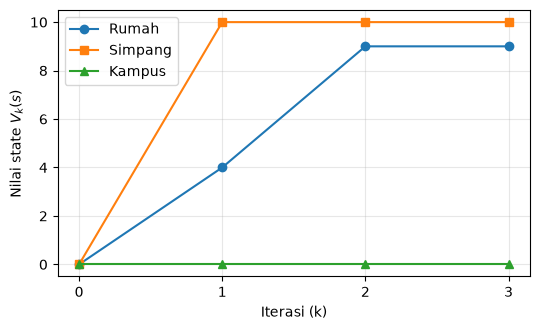

In [15]:
import matplotlib.pyplot as plt

iterasi = list(range(len(riwayat)))
plt.figure(figsize=(5.5, 3.4))
for state, penanda in [("Rumah", "o"), ("Simpang", "s"), ("Kampus", "^")]:
    plt.plot(iterasi, [v[state] for v in riwayat], marker=penanda, label=state)
plt.xlabel("Iterasi (k)")
plt.ylabel(r"Nilai state $V_k(s)$")
plt.xticks(iterasi)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

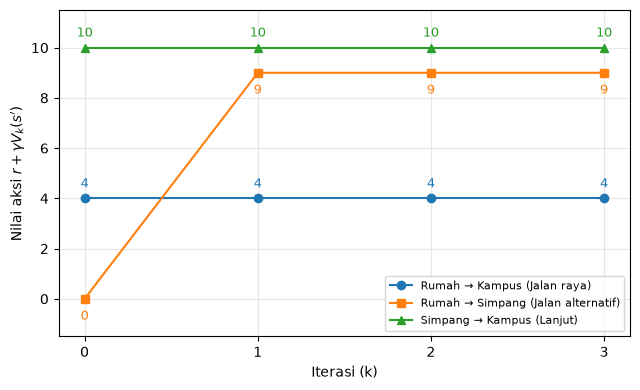

In [4]:
import matplotlib.pyplot as plt

# (label, state asal, nama aksi, penanda, warna, posisi angka)
garis = [
    ("Rumah → Kampus (Jalan raya)",        "Rumah",   "Jalan raya",       "o", "tab:blue",   (0, 8)),
    ("Rumah → Simpang (Jalan alternatif)", "Rumah",   "Jalan alternatif", "s", "tab:orange", (0, -15)),
    ("Simpang → Kampus (Lanjut)",          "Simpang", "Lanjut",           "^", "tab:green",  (0, 8)),
]

iterasi = list(range(len(riwayat)))   # iterasi 0 sampai 3

plt.figure(figsize=(6.5, 4))
for label, state, nama_aksi, penanda, warna, geser in garis:
    # ambil reward dan tujuan dari aksi tersebut
    _, tujuan, reward = next(a for a in MDP[state] if a[0] == nama_aksi)
    # nilai aksi pada iterasi k dihitung dari V_k (riwayat[k])
    nilai = [nilai_aksi(riwayat[k], reward, tujuan, GAMMA) for k in iterasi]
    plt.plot(iterasi, nilai, marker=penanda, color=warna, label=label)
    for k, y in zip(iterasi, nilai):
        plt.annotate(f"{round(y, 2):g}", (k, y), textcoords="offset points",
                     xytext=geser, ha="center", color=warna, fontsize=9)

plt.xlabel("Iterasi (k)")
plt.ylabel(r"Nilai aksi $r + \gamma V_k(s')$")
plt.xticks(iterasi)
plt.ylim(-1.5, 11.5)
plt.grid(alpha=0.3)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()